## A Mathematical Introduction to Machine Learning (5MA206), HT26
# Computer lab 1, part B: principal component analysis

**Instructions**
* Work through the notebook from top to bottom. Complete the code cells marked `# EDIT`, and answer the numbered
  questions **Q1, Q2, …** in the text cells below them.
* You may work in pairs. Write both names below.
* Before you submit: restart the kernel and run all cells (*Kernel* menu), and check that the notebook runs from start to
  finish without errors.
* Lab 1 consists of part A (linear regression) and part B (this notebook). Submit both notebooks together as one zip file on Canvas.

**Names:** Michael Sederlund Evans

PCA finds an $M$-dimensional subspace that the data lie close to (Lectures 5–6, MML Chapter 10). For **centred** data
$\boldsymbol x_1,\dots,\boldsymbol x_N\in\mathbb R^D$ (mean $\boldsymbol 0$) we

1. compute the data covariance matrix $\boldsymbol S=\frac1N\sum_{n=1}^N\boldsymbol x_n\boldsymbol x_n^\top$ and its
   eigenvalues $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_D\ge0$ with orthonormal eigenvectors
   $\boldsymbol u_1,\dots,\boldsymbol u_D$,
2. put the first $M$ eigenvectors as columns in $\boldsymbol B=[\boldsymbol u_1,\dots,\boldsymbol u_M]\in\mathbb R^{D\times M}$,
3. compute the **codes** $\boldsymbol z_n=\boldsymbol B^\top\boldsymbol x_n\in\mathbb R^M$ and the **reconstructions**
   $\tilde{\boldsymbol x}_n=\boldsymbol B\boldsymbol z_n=\boldsymbol B\boldsymbol B^\top\boldsymbol x_n$.

Among all $M$-dimensional subspaces this one gives the smallest average squared reconstruction error, and
$$
J_M=\frac1N\sum_{n=1}^N\|\boldsymbol x_n-\tilde{\boldsymbol x}_n\|^2=\sum_{m=M+1}^D\lambda_m
\qquad\text{(the variance in the discarded directions).}
$$

**Convention.** In code, a data set is stored with one example per **row**: $\boldsymbol X\in\mathbb R^{N\times D}$ has
the rows $\boldsymbol x_n^\top$. This is the transpose of the $D\times N$ matrix in MML Chapter 10 and in Lectures 5–6.
Then $\boldsymbol S=\frac1N\boldsymbol X^\top\boldsymbol X$, the codes are the rows of $\boldsymbol Z=\boldsymbol X\boldsymbol B$
($N\times M$), and the reconstructions are the rows of $\tilde{\boldsymbol X}=\boldsymbol Z\boldsymbol B^\top$ ($N\times D$).

**Packages.** The next cell installs the packages this lab needs, if they are missing (this needs an internet
connection). If they are already installed, as in Google Colab or a Miniforge environment set up as on the lab slides,
it only prints `Requirement already satisfied`. If it installed something new and an import below fails, restart the
kernel (*Kernel* menu) and run the notebook again.

In [ ]:
# pandas is used by fetch_openml (no comments on the %pip line: Windows would pass them to pip)
%pip install numpy matplotlib scikit-learn pandas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
rng = np.random.default_rng(1)   # fixed seed: everybody gets the same data

## 1. PCA in two dimensions

We start with $N=200$ points in $\mathbb R^2$. First centre the data: compute the mean $\boldsymbol\mu$ (a vector with
$D=2$ entries) and subtract it from every row.

mean of the centred data: [1.17572618e-15 2.20934382e-16]


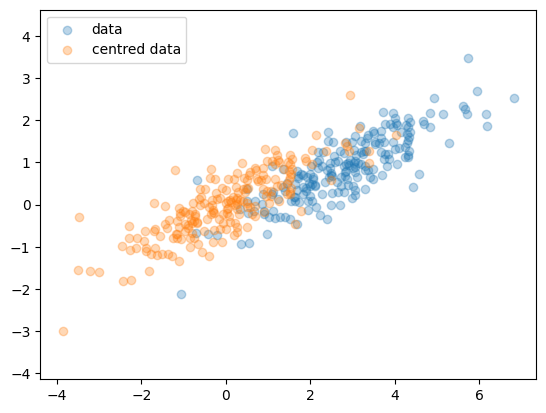

In [2]:
A = np.array([[1.5, 0.0], [0.8, 0.5]])
X_raw = rng.normal(size=(200, 2)) @ A.T + np.array([3.0, 1.0])
N, D = X_raw.shape

mu = np.mean(X_raw, axis=0) 
X = X_raw - mu        # centred data: every row minus mu
print('mean of the centred data:', X.mean(axis=0))

plt.figure()
plt.scatter(X_raw[:, 0], X_raw[:, 1], alpha=0.3, label='data')
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label='centred data')
plt.axis('equal'); plt.legend();

Complete the computation of $\boldsymbol S$. The function `np.linalg.eigh` computes the eigenvalues and orthonormal
eigenvectors of a symmetric matrix, with the eigenvalues in **increasing** order, so we reverse the order. The columns of
`U` are the eigenvectors $\boldsymbol u_1,\boldsymbol u_2$.

S =
 [[1.87285098 0.8945273 ]
 [0.8945273  0.62595195]]
eigenvalues: [2.33975387 0.15904905]
eigenvectors (columns):
 [[-0.88650639  0.46271635]
 [-0.46271635 -0.88650639]]
variance of the data along u_1: 2.339753874934739


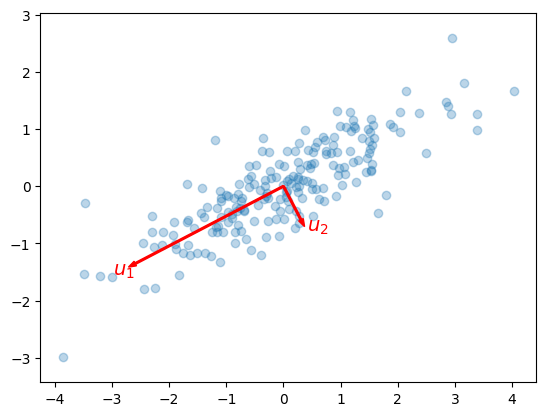

In [3]:
S = X.T @ X / N   # covariance matrix of the centred data
lam, U = np.linalg.eigh(S)
lam, U = lam[::-1], U[:, ::-1]     # decreasing order
print('S =\n', S)
print('eigenvalues:', lam)
print('eigenvectors (columns):\n', U)

z1 = X @ U[:, 0]   # the coordinates of all points along u_1
print('variance of the data along u_1:', np.mean(z1**2))

plt.figure()
plt.scatter(X[:, 0], X[:, 1], alpha=0.3)
for m in range(2):
    v = 2*np.sqrt(lam[m])*U[:, m]    # arrow of length 2 standard deviations along u_m
    plt.arrow(0, 0, v[0], v[1], color='r', width=0.03, length_includes_head=True)
    plt.text(1.1*v[0], 1.1*v[1], f'$u_{m+1}$', color='r', fontsize=14)
plt.axis('equal');

**Q1.** What does the eigenvalue $\lambda_1$ tell you about the data, and how does the cell above confirm it? Why is
$\boldsymbol u_1$ the direction in which the data vary the most? (Lecture 5)

$\lambda_1$ is the variance of the data along the direction $\boldsymbol u_1$, meaning how spread out the points are along that direction. This is confirmed by the cell as we can see as the variance of the coordinates $z_1 = \boldsymbol u_1^\top\boldsymbol x_n$ is $2.3398$, exactly $\lambda_1 = 2.3398$.

The variance of the data along any unit vector $\boldsymbol u$ is $\boldsymbol u^\top\boldsymbol S\boldsymbol u$. This is largest when $\boldsymbol u$ is the eigenvector with the largest eigenvalue, and then it equals $\lambda_1$. So $\boldsymbol u_1$ is the direction in which the data vary the most, as we can observe from the figure above.

### Codes and reconstructions
Now use only $M=1$ component. Complete the code for $\boldsymbol B$, the codes $\boldsymbol Z$ and the
reconstructions $\tilde{\boldsymbol X}$ (see the convention above), and compute the reconstruction error $J_1$.

J_1 = 0.1590
eigenvalues: [2.33975387 0.15904905]


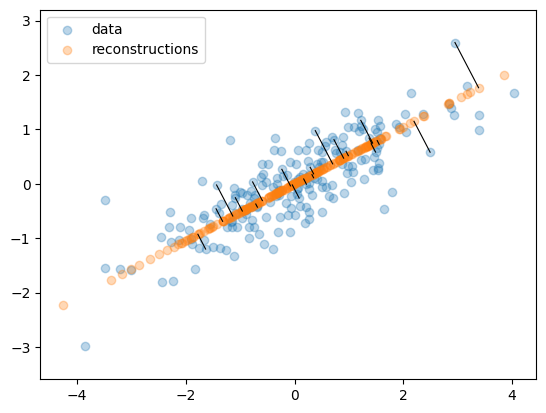

In [5]:
M = 1
B = U[:, :M]   # the first M eigenvectors (D x M)
Z = X @ B       # the coordinates of all points along u_1 (N x M)
X_rec = Z @ B.T   # the reconstructions (N x D)

J = np.mean(np.sum((X - X_rec)**2, axis=1))   # (1/N) sum_n ||x_n - x~_n||^2
print(f'J_1 = {J:.4f}')
print('eigenvalues:', lam)

plt.figure()
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label='data')
plt.scatter(X_rec[:, 0], X_rec[:, 1], alpha=0.3, label='reconstructions')
for n in range(0, N, 10):   # every 10th point and its reconstruction
    plt.plot([X[n, 0], X_rec[n, 0]], [X[n, 1], X_rec[n, 1]], 'k-', lw=0.8)
plt.axis('equal'); plt.legend();

**Q2.** Which eigenvalue is $J_1$ equal to, and why? Why are the black line segments (from $\boldsymbol x_n$ to
$\tilde{\boldsymbol x}_n$) perpendicular to $\boldsymbol u_1$? (Lectures 5–6)

The cell gives $J_1 = 0.1590$, which equals the second eigenvalue $\lambda_2 = 0.1590$. With $M = 1$ we keep only the direction $\boldsymbol u_1$ and throw away $\boldsymbol u_2$, so the information lost is exactly the variance in the discarded direction, which is $\lambda_2$ (from $J_M = \sum_{m>M}\lambda_m$).

The reconstruction $\tilde{\boldsymbol x}_n$ is the orthogonal projection of $\boldsymbol x_n$ onto the line through $\boldsymbol u_1$, the closest point on that line. The part that is removed, $\boldsymbol x_n - \tilde{\boldsymbol x}_n$, points along $\boldsymbol u_2$, which is perpendicular to $\boldsymbol u_1$. So the black segments are perpendicular to $\boldsymbol u_1$.

### A PCA routine
Collect the steps in a function. It is used for the rest of the lab.

In [6]:
def pca(X, M):
    # X: centred data (N x D), one example per row.  M: the number of components.
    # Returns B (D x M), whose columns are the first M principal directions, and
    # lam, all D eigenvalues of S in decreasing order.
    N, D = X.shape
    S = X.T @ X / N
    lam, U = np.linalg.eigh(S)
    lam, U = lam[::-1], U[:, ::-1]
    lam = np.maximum(lam, 0)    # zero eigenvalues can come out as -1e-17 because of rounding
    B = U[:, :M]
    return B, lam

B, lam = pca(X, 1)
print(B.ravel(), lam)    # should agree with the results above (B may have the opposite sign)

[-0.88650639 -0.46271635] [2.33975387 0.15904905]


## 2. Units and standardisation

PCA depends on the units of the features. Here are (synthetic) heights in metres and weights in kilograms of 200
people. Complete `standardize`, which divides every centred feature by its standard deviation.

variances: height 0.0104 m^2 = 103.5 cm^2, weight 100.0 kg^2


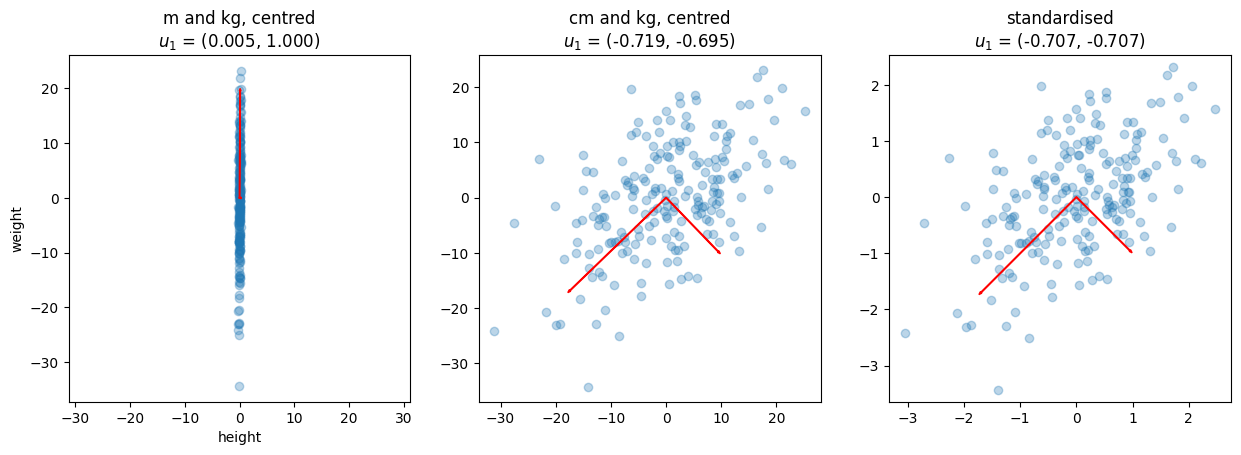

In [7]:
height = 1.75 + 0.10*rng.normal(size=200)                        # metres
weight = 75 + 50*(height - 1.75) + 8*rng.normal(size=200)       # kilograms

def centre(X):
    return X - X.mean(axis=0)

def standardize(X):
    # centre every feature (column) and divide it by its standard deviation
    return (X - X.mean(axis=0)) / X.std(axis=0)

def plot_pc(ax, X, title):
    B, lam = pca(X, 2)
    ax.scatter(X[:, 0], X[:, 1], alpha=0.3)
    for m in range(2):
        v = 2*np.sqrt(lam[m])*B[:, m]
        ax.arrow(0, 0, v[0], v[1], color='r', width=0.01*np.sqrt(lam[0]), length_includes_head=True)
    ax.set_title(title + f'\n$u_1$ = ({B[0, 0]:.3f}, {B[1, 0]:.3f})'); ax.axis('equal')

print(f'variances: height {height.var():.4f} m^2 = {(100*height).var():.1f} cm^2, weight {weight.var():.1f} kg^2')
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
plot_pc(ax[0], centre(np.column_stack([height, weight])), 'm and kg, centred')
plot_pc(ax[1], centre(np.column_stack([100*height, weight])), 'cm and kg, centred')
plot_pc(ax[2], standardize(np.column_stack([height, weight])), 'standardised')
ax[0].set_xlabel('height'); ax[0].set_ylabel('weight');

**Q3.** Explain the direction of $\boldsymbol u_1$ in each of the three plots. Why does the first principal component
follow the weight when height is measured in metres? What changes in centimetres, and what happens to the standardised
data if you change the units? When should you standardise before PCA? (Lecture 6)

* **Metres and kilograms:** $\boldsymbol u_1 = (0.005, 1.000)$, which points almost entirely along weight. The variance of height is only $0.0104\ \text{m}^2$, while weight has $100\ \text{kg}^2$. PCA looks for the direction with the largest variance, so it follows weight and practically ignores height. This happens only because of the units, not because height carries less information.
* **Centimetres and kilograms:** the variance of height becomes $103.5\ \text{cm}^2$, almost the same as weight's $100\ \text{kg}^2$. Now both features count about equally, and $\boldsymbol u_1 = (-0.719, -0.695)$ points diagonally along the cloud, showing that taller people tend to be heavier. The sign doesn't matter.
* **Standardised:** every feature has variance $1$, so $\boldsymbol u_1 = (-0.707, -0.707)$ is exactly diagonal and follows the correlation between height and weight. If you change the units, the standardised data do not change at all, because the scaling factor cancels when dividing by the standard deviation. So the result no longer depends on the units.

When the features are measured in different units or on very different scales you should standardise, so that no feature dominates just because of its unit. If all features have the same unit and their scale is meaningful, it is usually better not to standardise.

## 3. Handwritten digits (MNIST)

MNIST consists of $70\,000$ greyscale images of handwritten digits, $28\times28$ pixels, so $D=784$. The first
$60\,000$ are the official training set. The next cell downloads the data (about 15 MB) from openml.org, which can take
a minute; scikit-learn stores a copy on your computer, so it is fast the next time.

In [8]:
from sklearn.datasets import fetch_openml
images, labels = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
print(images.shape, labels[:10])    # the labels are strings '0', ..., '9'

(70000, 784) ['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']


We use the first $N=1000$ images, with the pixel values scaled to $[0,1]$, and centre them. The mean $\boldsymbol\mu$ is
itself an image.

number of pixels that are 0 in all 1000 images: 175


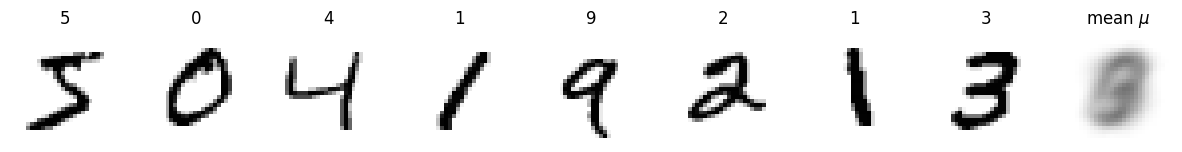

In [9]:
N_img = 1000
X_img = images[:N_img] / 255
y_img = labels[:N_img]
mu_img = X_img.mean(axis=0)
X = X_img - mu_img          # centred data, N x 784

def show(ax, x, title=''):
    ax.imshow(x.reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(title); ax.axis('off')

fig, ax = plt.subplots(1, 9, figsize=(15, 2))
for i in range(8):
    show(ax[i], X_img[i], y_img[i])
show(ax[8], mu_img, 'mean $\\mu$')

print('number of pixels that are 0 in all 1000 images:', np.sum(X_img.std(axis=0) == 0))

**Q4.** In Section 2 we standardised the features. Why is it better not to standardise the pixels here? (Look at the
output of the cell above.)

The cell shows that 175 pixels are $0$ in all 1000 images. These pixels never change, so their standard deviation is $0$. Standardising divides each pixel by its standard deviation, so for these pixels we would divide by zero, which breaks PCA.
The pictures also show that the digits are drawn in the middle of the image, and the mean image $\boldsymbol\mu$ is white near the edges. So pixels near the edge are almost never used and vary very little. Standardising would give every pixel variance $1$, so these rarely used pixels would count as much as the pixels in the middle that actually form the digits.

Standardising is not needed here anyway as all pixels have the same unit with a brightness from $0$ to $1$, so the problem from Section 2 with different units does not occur.

### How many components?
The fraction of the variance kept by $M$ components is $V_M/V_D=\sum_{m\le M}\lambda_m\big/\sum_{m=1}^D\lambda_m$.
Find the smallest $M$ that keeps 90% and 99% of the variance.

M for 90%: 76    M for 99%: 276
number of eigenvalues > 1e-10: 590


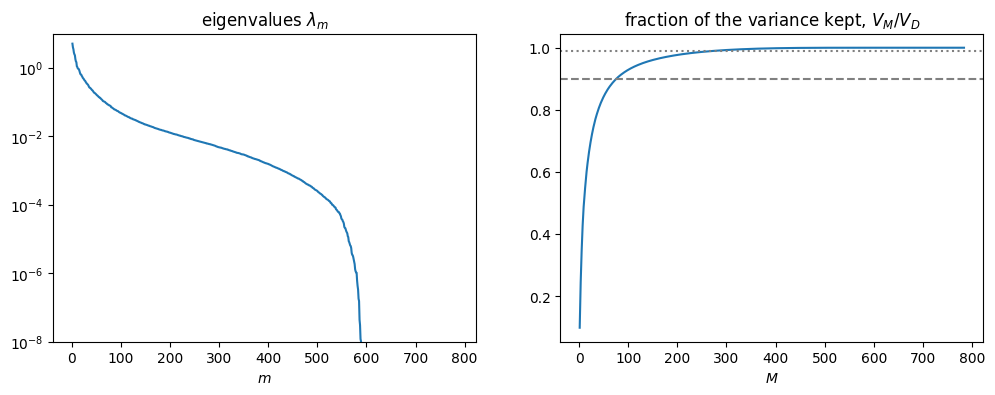

In [10]:
B, lam = pca(X, 784)               # all 784 principal directions
frac = np.cumsum(lam) / np.sum(lam)   # frac[M-1] = V_M / V_D
M90 = np.argmax(frac >= 0.9) + 1   
M99 = np.argmax(frac >= 0.99) + 1   
print('M for 90%:', M90, '   M for 99%:', M99)
print('number of eigenvalues > 1e-10:', np.sum(lam > 1e-10))

Ms = np.arange(1, 785)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(Ms, lam + 1e-20); ax[0].set_ylim(1e-8, 10)
ax[0].set_xlabel('$m$'); ax[0].set_title('eigenvalues $\\lambda_m$')
ax[1].plot(Ms, frac); ax[1].axhline(0.9, ls='--', c='gray'); ax[1].axhline(0.99, ls=':', c='gray')
ax[1].set_xlabel('$M$'); ax[1].set_title('fraction of the variance kept, $V_M/V_D$');

**Q5.** How many components keep 90% and 99% of the variance? Many of the 784 eigenvalues are zero (up to rounding).
Why? (Hint: what is $\boldsymbol S\boldsymbol e_d$ if pixel $d$ is $0$ in every image?)

$M = 76$ components keep 90% of the variance and $M = 276$ keep 99%, out of $D = 784$. So most of the information in the images can be described with far fewer numbers than 784 pixels.

Only $590$ eigenvalues are larger than $10^{-10}$, so $784 - 590 = 194$ are zero. The reason is the pixels that are $0$ in every image. If pixel $d$ is always $0$, then column $d$ of the centred data $\boldsymbol X$ is all zeros, so $\boldsymbol X\boldsymbol e_d = \boldsymbol 0$ and
$$
\boldsymbol S\boldsymbol e_d = \tfrac{1}{N}\boldsymbol X^\top\boldsymbol X\boldsymbol e_d = \boldsymbol 0 = 0\cdot\boldsymbol e_d .
$$
So $\boldsymbol e_d$ is an eigenvector with eigenvalue $0$ which means that there is no variance in that direction. This gives $175$ zero eigenvalues, one for each always-zero pixel from Q4. The remaining $19$ come from pixels that are used in only a few images. Their columns in $\boldsymbol X$ are linearly dependent, so they also give directions with no variance.

### Reconstruction error, on the data and on new images
The formula $J_M=\sum_{m>M}\lambda_m$ gives the reconstruction error for every $M$ at once. Check it by computing $J_M$
directly from the reconstructions for some values of $M$. Then compute the error for $1000$ **new** images (from the
official test set), reconstructed with the **same** $\boldsymbol\mu$ and $\boldsymbol B$.

M =   1:  sum of discarded eigenvalues 46.4654,  J_M 46.4654,  new images 47.6348
M =   2:  sum of discarded eigenvalues 42.4643,  J_M 42.4643,  new images 44.5849
M =   5:  sum of discarded eigenvalues 33.6244,  J_M 33.6244,  new images 36.4442
M =  10:  sum of discarded eigenvalues 25.3197,  J_M 25.3197,  new images 28.3597
M =  20:  sum of discarded eigenvalues 17.2900,  J_M 17.2900,  new images 20.2916
M =  50:  sum of discarded eigenvalues 8.0776,  J_M 8.0776,  new images 10.3016
M = 100:  sum of discarded eigenvalues 3.6566,  J_M 3.6566,  new images 5.3573
M = 200:  sum of discarded eigenvalues 1.1940,  J_M 1.1940,  new images 2.4361
M = 400:  sum of discarded eigenvalues 0.0837,  J_M 0.0837,  new images 0.4376
M = 600:  sum of discarded eigenvalues 0.0000,  J_M 0.0000,  new images 0.0065
M = 784:  sum of discarded eigenvalues 0.0000,  J_M 0.0000,  new images 0.0000


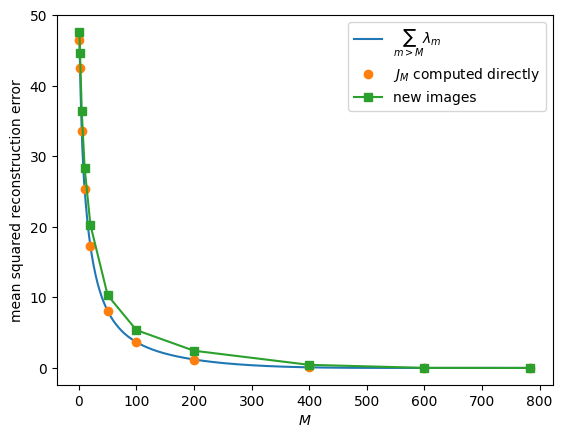

In [11]:
J_eig = np.sum(lam) - np.cumsum(lam)       # J_eig[M-1] = sum of lambda_m for m > M

X_new = images[60000:61000] / 255 - mu_img   # new images, centred with the mean of the old ones

M_list = [1, 2, 5, 10, 20, 50, 100, 200, 400, 600, 784]
J_direct, J_new = [], []
for M in M_list:
    B_M = B[:, :M]
    X_rec = X @ B_M @ B_M.T   
    X_new_rec = X_new @ B_M @ B_M.T
    J_direct.append(np.mean(np.sum((X - X_rec)**2, axis=1)))
    J_new.append(np.mean(np.sum((X_new - X_new_rec)**2, axis=1)))
    print(f'M = {M:3d}:  sum of discarded eigenvalues {J_eig[M-1]:.4f},  J_M {J_direct[-1]:.4f},  new images {J_new[-1]:.4f}')

plt.figure()
plt.plot(Ms, J_eig, label='$\\sum_{m>M}\\lambda_m$')
plt.plot(M_list, J_direct, 'o', label='$J_M$ computed directly')
plt.plot(M_list, J_new, 's-', label='new images')
plt.xlabel('$M$'); plt.ylabel('mean squared reconstruction error'); plt.legend();

**Q6.** Do the two ways of computing $J_M$ agree? Why is the error for the new images larger? Explain in particular why
it is not $0$ for $M=600$, and why it is $0$ for $M=784$. (Compare with training and test error in Lectures 2 and 4.)

Yes, the two ways agree exactly. For every $M$, the directly computed $J_M$ equals the sum of the discarded eigenvalues $\sum_{m>M}\lambda_m$, for example $8.0776$ for $M = 50$.

The error for the new images is larger because PCA was computed from the old images only. The directions $\boldsymbol u_1, \dots, \boldsymbol u_M$ are chosen to fit the old images as well as possible, so the error on them is like a training error. The new images have not been seen, so their error is like a test error, and it is usually larger.

**$M = 600$:** the old images only vary in $590$ directions (Q5), so $600$ directions capture everything about them and the error is $0$. But a new image can have ink in places that were never used in the old images, for example in some of the 175 pixels that were always $0$. Those directions are not among the $600$ kept ones, so that part of the new image is lost and the error is not $0$, instead it is $0.0065$.

**$M = 784$:** we keep all $784$ directions. They form a complete basis of $\mathbb R^{784}$, so every image, old or new, can be rebuilt exactly ($\boldsymbol B\boldsymbol B^\top = \boldsymbol I$). Nothing is thrown away, so the error is $0$.

### What the reconstructions look like
Each row shows one image, then its reconstructions $\boldsymbol\mu+\tilde{\boldsymbol x}_n$ with $M$ components.

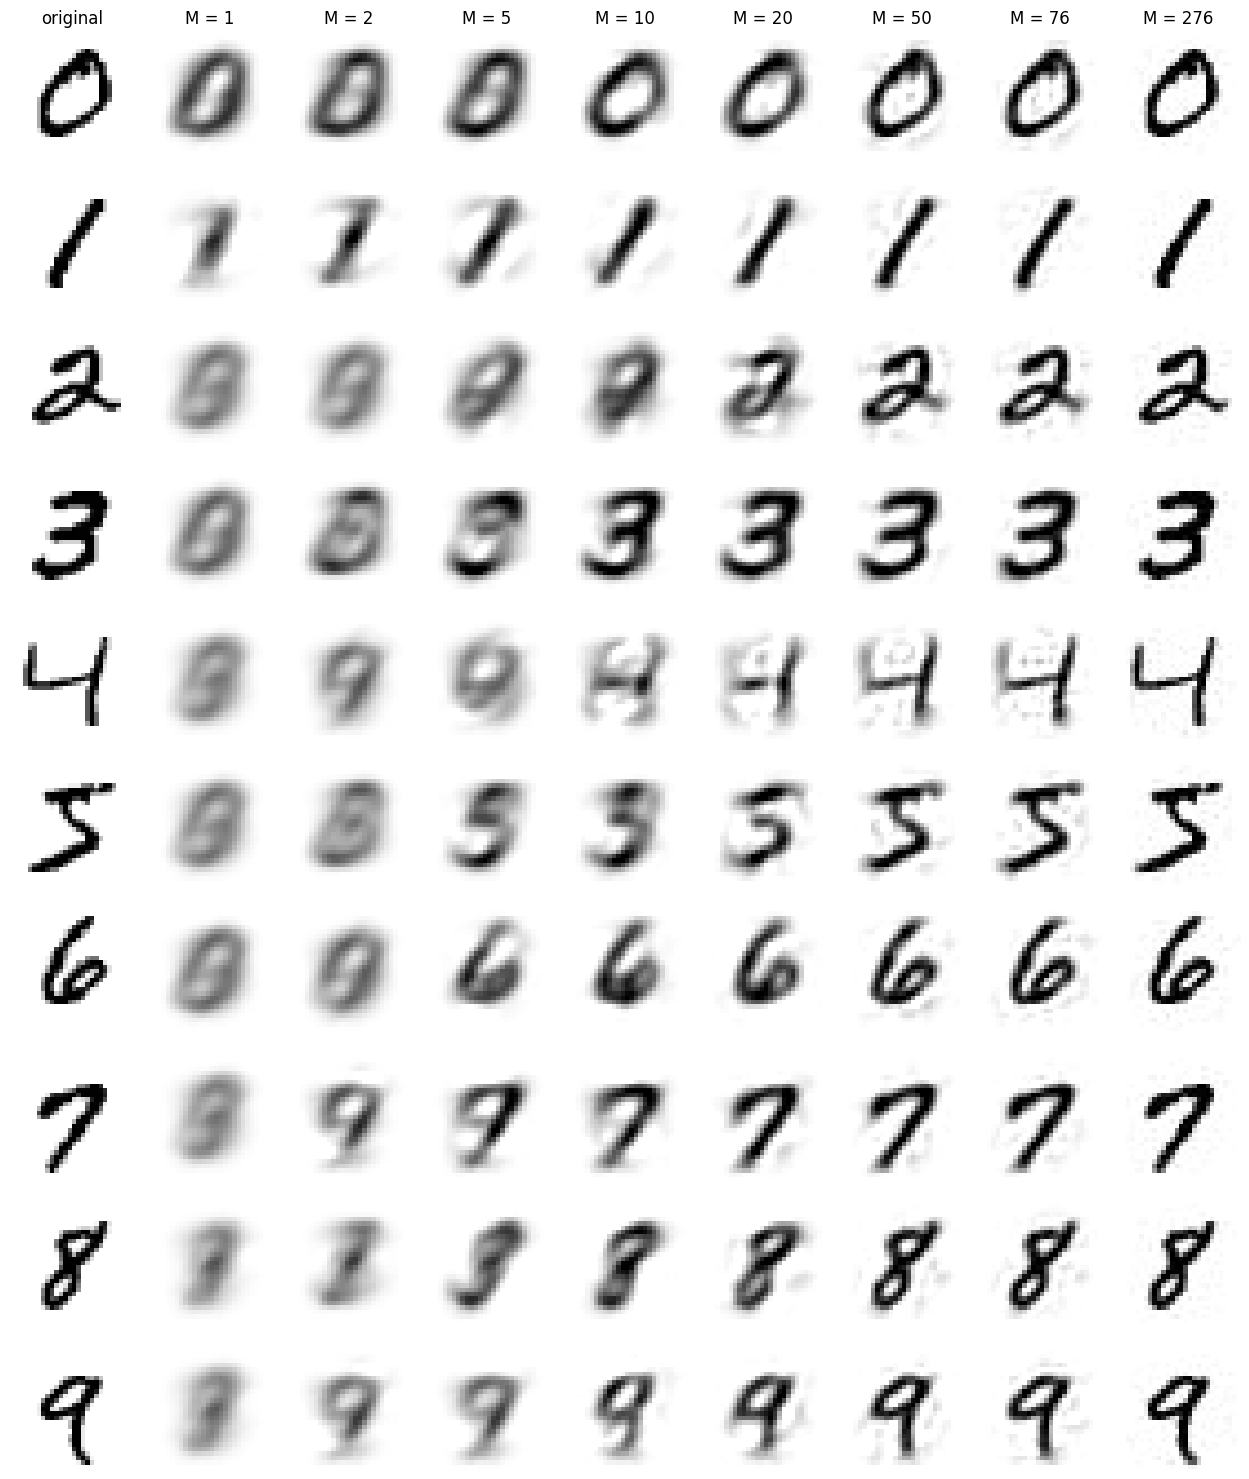

In [12]:
M_show = [1, 2, 5, 10, 20, 50, M90, M99]
idx = [list(y_img).index(str(d)) for d in range(10)]   # the first image of every digit
fig, ax = plt.subplots(len(idx), len(M_show) + 1, figsize=(1.4*(len(M_show) + 1), 1.5*len(idx)))
for r, n in enumerate(idx):
    show(ax[r, 0], X_img[n], 'original' if r == 0 else '')
    for c, M in enumerate(M_show):
        x_rec = mu_img + X[n] @ B[:, :M] @ B[:, :M].T
        show(ax[r, c + 1], np.clip(x_rec, 0, 1), f'M = {M}' if r == 0 else '')
plt.tight_layout()

The principal directions $\boldsymbol u_m$ are also images ("eigendigits"). Red pixels are positive and blue pixels
negative; the code $z_m=\boldsymbol u_m^\top\boldsymbol x$ is large when the centred image looks like $\boldsymbol u_m$.

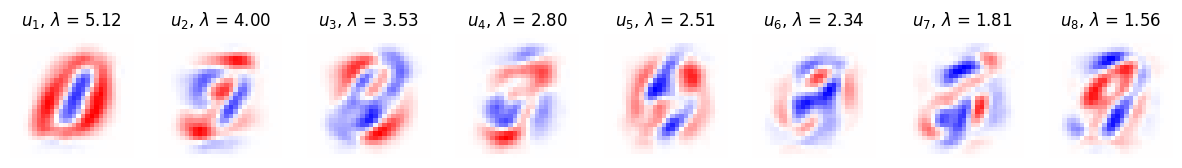

In [13]:
fig, ax = plt.subplots(1, 8, figsize=(15, 2))
for m in range(8):
    a = np.abs(B[:, m]).max()
    ax[m].imshow(B[:, m].reshape(28, 28), cmap='bwr', vmin=-a, vmax=a)
    ax[m].set_title(f'$u_{{{m+1}}}$, $\\lambda$ = {lam[m]:.2f}'); ax[m].axis('off')

**Q7.** How many components do you need before you can recognise all ten digits in the reconstructions? Which digits
are reconstructed well with very few components, and which need many? Is keeping 90% of the variance enough to
recognise the digits?

From about $M = 50$ components all ten digits can be recognised. The $4$ is still a bit unclear at $M = 50$, but readable if you know what to look for.

* Reconstructed well with few components: $0$ and $1$, and also $3$, $6$, $7$ and $9$ at about $M = 10$. These have simple, common shapes. The $0$ is already visible at $M = 1$–$2$, because $\boldsymbol u_1$ itself looks like a $0$ (a red ring with blue in the middle), so the first component captures exactly that shape.
* Need many components: $4$, and to some extent $2$, while $5$ and $8$ need about $M = 20$. With few components they look like a blurry average digit, often like a $9$ or $0$. The $4$ has an unusual open shape with straight lines that doesn't resemble the first eigendigits, so it is not clear until $M \approx 50$–$76$.

Keeping 90% of the variance, M=76 is enough, as at that stage I would say that all digits are clearly recognisble, only slightly blurry blurry and with some grey specks.

## 4. Two-dimensional codes

With $M=2$, every image is represented by two numbers $(z_1,z_2)$, so the whole data set can be plotted
(compare MML Figure 10.10). Here are all $1000$ images, coloured by their label.

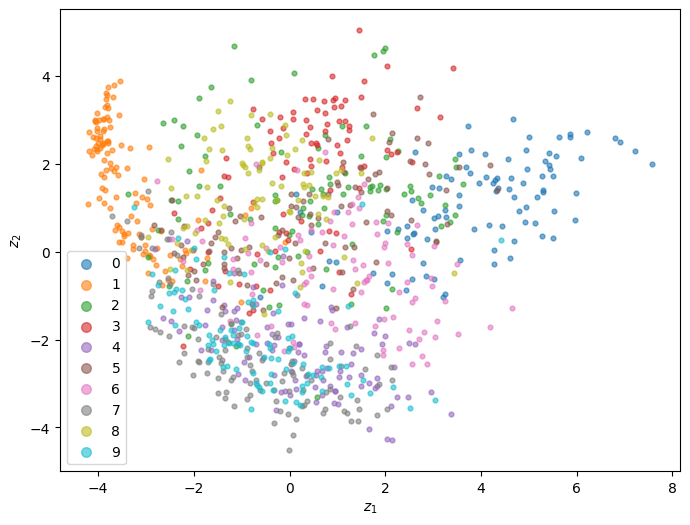

In [14]:
Z = X @ B[:, :2]
plt.figure(figsize=(8, 6))
for d in range(10):
    plt.scatter(Z[y_img == str(d), 0], Z[y_img == str(d), 1], s=12, alpha=0.6, color=plt.cm.tab10(d), label=str(d))
plt.xlabel('$z_1$'); plt.ylabel('$z_2$'); plt.legend(markerscale=2);

Plot two of the digits at a time. Change the pair and rerun the cell.

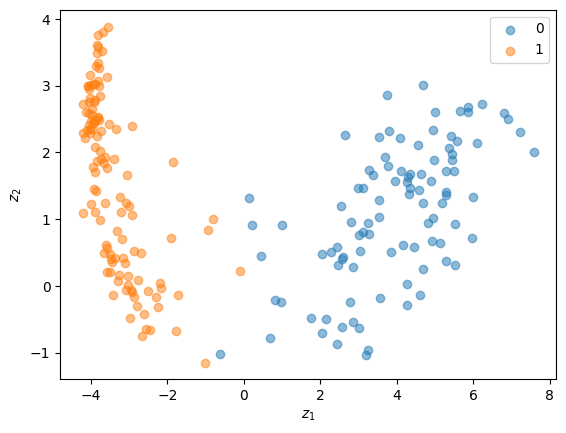

In [21]:
a, b = '0', '1'    # 0 and 1 seems to be the easiest pair to separate
plt.figure()
plt.scatter(Z[y_img == a, 0], Z[y_img == a, 1], alpha=0.5, label=a)
plt.scatter(Z[y_img == b, 0], Z[y_img == b, 1], alpha=0.5, label=b)
plt.xlabel('$z_1$'); plt.ylabel('$z_2$'); plt.legend();

**Q8.** A classifier must separate the points of different classes. Which pair of digits is easiest to separate using
only $(z_1,z_2)$, and which pair is hard? Show the plot for your easiest pair, and explain it with the images
$\boldsymbol u_1$ and $\boldsymbol u_2$ above.

**Q9.** PCA does not use the labels. Is the best 2-dimensional subspace for reconstruction (PCA) necessarily the best one
for separating two classes? Explain briefly.

**Q8.** The easiest pair is $0$ and $1$. The 1s lie far to the left, $z_1 \approx -4$ to $-1.5$, and the 0s far to the right, $z_1 \approx 1$ to $7.5$. The two clouds hardly overlap, so a line around $z_1 \approx 0$ separates them almost perfectly.

A hard pair is $4$ and $9$, whose points lie on top of each other, so no line can separate them without many mistakes. The pairs $7$ and $9$, and $3$ and $5$, are also hard.

This is explained by the eigendigits. $\boldsymbol u_1$ is a red ring with blue in the middle, so it looks like a $0$. A $0$ has ink on the ring and gets a large positive $z_1$. A $1$ is a stroke through the middle with no ink on the ring, so it gets a large negative $z_1$. This means $z_1$ alone separates $0$ and $1$, and $\boldsymbol u_2$ is not needed for this pair.

$\boldsymbol u_2$ instead separates groups of digits. In the scatter plot $z_2$ is positive for $0$, $1$ and $3$ and negative for $4$, $7$ and $9$. So $\boldsymbol u_2$ responds to the shape that $4$, $7$ and $9$ share, a stroke down the right side with something across the top. Since $4$ and $9$ match both $\boldsymbol u_1$ and $\boldsymbol u_2$ in the same way, they get similar codes. What tells them apart is whether the top is closed, a small detail that neither component captures.

**Q9.** No. PCA chooses the directions with the largest variance and never looks at the labels. The direction that separates two classes may have small variance, so PCA can throw it away. For example, $4$ and $9$ differ mainly in the small detail whether the top is closed, which carries little variance, so it is not captured by $\boldsymbol u_1$ and $\boldsymbol u_2$.

## Optional extras
* Repeat Section 3 with all $60\,000$ training images (computing $\boldsymbol S$ takes a few seconds). How do $M_{90}$
  and the error for new images change?
* Compute the principal directions with the SVD of $\boldsymbol X$ (`np.linalg.svd`, Lecture 6) and compare with `eigh`.
* Compare with `sklearn.decomposition.PCA`.